In [1]:
# --------- 1 ------------


import numpy as np
import pandas as pd

from lightgbm import LGBMRegressor

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

from sklearn.model_selection import KFold

In [2]:
df = pd.read_parquet("/home/prasanna/Ishan/ACRI_Data_Prep_Analysis/final_training_ACRI_1998_2025.parquet")
df.head(3)

,latitude,longitude,Year,Month,month_sin,month_cos,zos,so,thetao,uo,vo,mlotst_ln,vorticity,okubo_weiss,grad_ssh,chlor_a_log10
0,5.083333,48.416668,1998,1,0.5,0.866025,0.356643,35.085851,27.240661,-0.214890,-0.258462,3.203022,-0.000001,-4.432381e-13,7.225481e-07,-0.591444
1,5.083333,48.500000,1998,1,0.5,0.866025,0.350835,35.190106,27.319741,-0.217311,-0.259840,3.522403,-0.000005,-4.999900e-12,6.700163e-07,-0.677223
2,5.083333,48.583332,1998,1,0.5,0.866025,0.344721,35.220427,27.334367,-0.254780,-0.304201,3.699259,-0.000006,-1.445125e-11,6.258408e-07,-0.699379


In [3]:
# ---------- 2 ------------

df = pd.read_parquet("/home/prasanna/Ishan/ACRI_Data_Prep_Analysis/final_training_ACRI_1998_2025.parquet")

# -----------------------------
# BOB
# Lon: 45°E–65°E
# Lat: 5°N–28°N
# -----------------------------

df = df[
    (df["longitude"] >= 78) &
    (df["longitude"] <= 100) &
    (df["latitude"]  >= 5) &
    (df["latitude"]  <= 25)
].copy()

print(f"Total samples in BOB = {len(df):,}")

TARGET = "chlor_a_log10"

DROP_COLS = [
    TARGET,
    "latitude",
    "longitude",
    "Year",
    "Month",
    "zos",
    "grad_ssh"
    
]

# -----------------------------
# Train : 1998-2023
# Test  : 2024-2025
# -----------------------------

train_df = df[
    (df["Year"] >= 1998) &
    (df["Year"] <= 2023)
].copy()

test_df = df[
    (df["Year"] >= 2024) &
    (df["Year"] <= 2025)
].copy()

train_df = train_df.sort_values(
    ["Year", "Month"]
).reset_index(drop=True)

test_df = test_df.sort_values(
    ["Year", "Month"]
).reset_index(drop=True)

FEATURES = [
    col for col in df.columns
    if col not in DROP_COLS
]

X_train = train_df[FEATURES].astype("float32")
y_train = train_df[TARGET].astype("float32")

X_test = test_df[FEATURES].astype("float32")
y_test = test_df[TARGET].astype("float32")


X_train.head(3)

Total samples in BOB = 12,374,824


,month_sin,month_cos,so,thetao,uo,vo,mlotst_ln,vorticity,okubo_weiss
0,0.5,0.866025,32.927158,28.482037,-0.628051,0.018035,2.672194,-3.782050e-07,1.136766e-12
1,0.5,0.866025,32.925926,28.480122,-0.629882,0.011715,2.668445,-3.912286e-07,1.189989e-12
2,0.5,0.866025,32.925926,28.478634,-0.630729,0.004863,2.671173,-3.765727e-07,1.311214e-12


In [4]:
print(f"Training samples : {len(X_train):,}")
print(f"Testing samples  : {len(X_test):,}")
print(f"Number of features : {len(FEATURES)}")

Training samples : 11,490,908
Testing samples  : 883,916
Number of features : 9


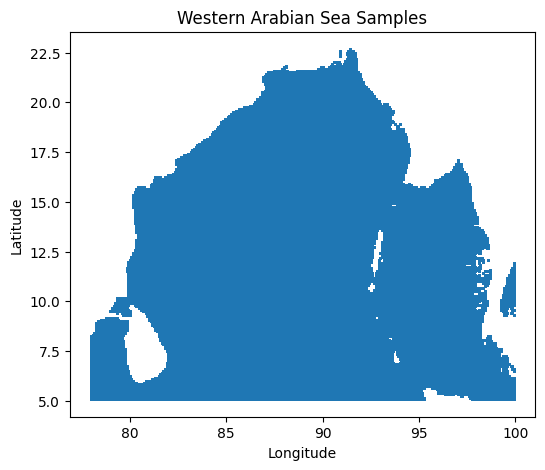

In [5]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,5))
plt.scatter(
    df["longitude"],
    df["latitude"],
    s=0.1,
    alpha=0.2
)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Western Arabian Sea Samples")
plt.show()

In [6]:
# --------- 3 --------------

# ============================================================
# Standard K-Fold Cross Validation
# ============================================================

kf = KFold(
    n_splits=2,
    shuffle=True,
    random_state=42
)

fold_indices = list(kf.split(X_train))

# ============================================================
# Check Folds
# ============================================================

for i, (train_idx, valid_idx) in enumerate(fold_indices, start=1):

    print(f"\nFold {i}")

    print(
        f"Train Samples: {len(train_idx):,}"
    )

    print(
        f"Valid Samples: {len(valid_idx):,}"
    )


Fold 1
Train Samples: 5,745,454
Valid Samples: 5,745,454

Fold 2
Train Samples: 5,745,454
Valid Samples: 5,745,454


In [7]:
UNDER_PENALTY = 0.0005

def underestimation_loss(y_true, y_pred):

    error = y_true - y_pred

    under_mask = error > 0

    grad = np.where(
        under_mask,
        -2.0 * (1.0 + UNDER_PENALTY) * error,
        -2.0 * error
    )

    hess = np.where(
        under_mask,
        2.0 * (1.0 + UNDER_PENALTY),
        2.0
    )

    return grad, hess

In [8]:
# ------------ 7 ---------------

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)



best_model_params = {

    "max_depth": 31,
    "num_leaves": 1472,
    "n_estimators": 664,
    "learning_rate": 0.027159147746761574,
    "subsample": 0.815488030873806,
    "colsample_bytree": 0.8417991614120953,
    "min_child_samples": 43,
    "min_split_gain": 0.83270225900222,
    "reg_alpha": 0.06613452649153007,
    "reg_lambda": 22.375526769921


}


results = []

for fold, (train_idx, valid_idx) in enumerate(
    fold_indices,
    start=1
):

    X_tr = X_train.iloc[train_idx]
    y_tr = y_train.iloc[train_idx]

    X_val = X_train.iloc[valid_idx]
    y_val = y_train.iloc[valid_idx]

    model = LGBMRegressor(
        objective=underestimation_loss,
        device="gpu",
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
        **best_model_params
    )
    model.fit(
    X_tr,
    y_tr
    #verbose=False
    )
    
    
    

    

    

    # ----------------------------------                 # Train- val metrics 
    # Train Metrics
    # ----------------------------------

    pred_train = model.predict(X_tr)

    train_r2 = r2_score(y_tr, pred_train)

    train_rmse = np.sqrt(
        mean_squared_error(y_tr, pred_train)
    )

    train_mae = mean_absolute_error(
        y_tr,
        pred_train
    )

    train_bias = np.mean(
        pred_train - y_tr
    )

    # ----------------------------------
    # Validation Metrics
    # ----------------------------------

    pred_val = model.predict(X_val)

    val_r2 = r2_score(y_val, pred_val)

    val_rmse = np.sqrt(
        mean_squared_error(y_val, pred_val)
    )

    val_mae = mean_absolute_error(
        y_val,
        pred_val
    )

    val_bias = np.mean(
        pred_val - y_val
    )

    print(f"\nFold {fold}")

    print(
        f"TRAIN      | "
        f"R²={train_r2:.5f} | "
        f"RMSE={train_rmse:.5f} | "
        f"MAE={train_mae:.5f} | "
        f"Bias={train_bias:.5f}"
    )

    print(
        f"VALIDATION | "
        f"R²={val_r2:.5f} | "
        f"RMSE={val_rmse:.5f} | "
        f"MAE={val_mae:.5f} | "
        f"Bias={val_bias:.5f}"
    )

    results.append([
        fold,
        train_r2,
        val_r2,
        train_rmse,
        val_rmse,
        train_mae,
        val_mae,
        train_bias,
        val_bias
    ])

cv_metrics_df = pd.DataFrame(
    results,
    columns=[
        "Fold",
        "Train_R2",
        "Val_R2",
        "Train_RMSE",
        "Val_RMSE",
        "Train_MAE",
        "Val_MAE",
        "Train_Bias",
        "Val_Bias"
    ]
)

print("\n")
print(cv_metrics_df)


summary_df = pd.DataFrame({

    "Metric": [
        "R2",
        "RMSE",
        "MAE",
        "Bias"
    ],

    "Train_Mean": [

        cv_metrics_df["Train_R2"].mean(),
        cv_metrics_df["Train_RMSE"].mean(),
        cv_metrics_df["Train_MAE"].mean(),
        cv_metrics_df["Train_Bias"].mean()
    ],

    "Validation_Mean": [

        cv_metrics_df["Val_R2"].mean(),
        cv_metrics_df["Val_RMSE"].mean(),
        cv_metrics_df["Val_MAE"].mean(),
        cv_metrics_df["Val_Bias"].mean()
    ]
})

print(summary_df)


# ============================================================
# CV Mean ± Std Summary
# ============================================================

cv_stats_df = pd.DataFrame({

    "Metric": [
        "R2",
        "RMSE",
        "MAE",
        "Bias"
    ],

    "Train_Mean": [

        cv_metrics_df["Train_R2"].mean(),
        cv_metrics_df["Train_RMSE"].mean(),
        cv_metrics_df["Train_MAE"].mean(),
        cv_metrics_df["Train_Bias"].mean()
    ],

    "Train_SD": [

        cv_metrics_df["Train_R2"].std(),
        cv_metrics_df["Train_RMSE"].std(),
        cv_metrics_df["Train_MAE"].std(),
        cv_metrics_df["Train_Bias"].std()
    ],

    "Validation_Mean": [

        cv_metrics_df["Val_R2"].mean(),
        cv_metrics_df["Val_RMSE"].mean(),
        cv_metrics_df["Val_MAE"].mean(),
        cv_metrics_df["Val_Bias"].mean()
    ],

    "Validation_SD": [

        cv_metrics_df["Val_R2"].std(),
        cv_metrics_df["Val_RMSE"].std(),
        cv_metrics_df["Val_MAE"].std(),
        cv_metrics_df["Val_Bias"].std()
    ]
})

print("\nCross-Validation Mean ± SD")
print(cv_stats_df)


Fold 1
TRAIN      | R²=0.78611 | RMSE=0.14565 | MAE=0.09803 | Bias=0.00048
VALIDATION | R²=0.77779 | RMSE=0.14837 | MAE=0.09940 | Bias=0.00032

Fold 2
TRAIN      | R²=0.78535 | RMSE=0.14582 | MAE=0.09818 | Bias=0.00048
VALIDATION | R²=0.77802 | RMSE=0.14837 | MAE=0.09950 | Bias=0.00054


   Fold  Train_R2    Val_R2  Train_RMSE  Val_RMSE  Train_MAE   Val_MAE  \
0     1  0.786110  0.777795    0.145645  0.148368   0.098035  0.099401   
1     2  0.785352  0.778021    0.145824  0.148374   0.098184  0.099502   

   Train_Bias  Val_Bias  
0    0.000482  0.000318  
1    0.000482  0.000537  
  Metric  Train_Mean  Validation_Mean
0     R2    0.785731         0.777908
1   RMSE    0.145735         0.148371
2    MAE    0.098110         0.099451
3   Bias    0.000482         0.000428

Cross-Validation Mean ± SD
  Metric  Train_Mean      Train_SD  Validation_Mean  Validation_SD
0     R2    0.785731  5.362357e-04         0.777908       0.000160
1   RMSE    0.145735  1.261157e-04         0.148371      

In [9]:
# --------------- 8 ------------------



final_model = LGBMRegressor(
    objective=underestimation_loss,
    device="gpu",
    random_state=42,
    n_jobs=-1,
    verbosity=-1,
    **best_model_params
)

final_model.fit(
    X_train,
    y_train
    #verbose=False
)

,boosting_type,'gbdt'
,num_leaves,1472
,max_depth,31
,learning_rate,0.027159147746761574
,n_estimators,664
,subsample_for_bin,200000
,objective,<function und...x7fecc91d56c0>
,class_weight,None
,min_split_gain,0.83270225900222
,min_child_weight,0.001
,min_child_samples,43


In [10]:

# -----------------------------
# Train Predictions
# -----------------------------
y_train_pred = final_model.predict(X_train)

# -----------------------------
# Train Metrics
# -----------------------------
train_r2   = r2_score(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_mae  = mean_absolute_error(y_train, y_train_pred)
train_bias = np.mean(y_train_pred - y_train)

# -----------------------------
# Print Results
# -----------------------------
print("\n==============================")
print("Training Performance")
print("==============================")
print(f"Train R²   : {train_r2:.4f}")
print(f"Train RMSE : {train_rmse:.4f}")
print(f"Train MAE  : {train_mae:.4f}")
print(f"Train Bias : {train_bias:.4f}")


Training Performance
Train R²   : 0.7907
Train RMSE : 0.1440
Train MAE  : 0.0968
Train Bias : 0.0004


In [11]:
# ------------------ 9 ----------------------

import joblib

# ============================================================
# Save Final Model
# ============================================================

MODEL_PATH = "ACRI_lGBM_BOB_model_sec_tuned_2.pkl"

joblib.dump(
    final_model,
    MODEL_PATH
)

print("\n" + "="*60)
print("MODEL SAVED SUCCESSFULLY")
print("="*60)
print(f"Saved as: {MODEL_PATH}")


MODEL SAVED SUCCESSFULLY
Saved as: ACRI_lGBM_BOB_model_sec_tuned_2.pkl
